In [18]:

import json
import math
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import cv2
import shutil

from PIL import Image
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    array_to_img,
    img_to_array,
    load_img
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score
import scipy
from tqdm import tqdm

# Set random seeds for reproducibility
np.random.seed(2019)
tf.random.set_seed(2019)

PROJECT_DIR = os.getcwd()

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


In [19]:
# Cell 2: Balance the dataset and generate augmented images

import os
import shutil
import pandas as pd
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img,
    img_to_array
)

# 1. Set local dataset paths
csv_path = os.path.join(PROJECT_DIR, "DR_grading.csv")
image_dir = os.path.join(PROJECT_DIR, "DR_grading", "DR_grading")
# Keep the archived Kaggle augmentation output and naming behavior.
output_dir = os.path.join(PROJECT_DIR, "working", "ddr-equal")

train_images_dir = os.path.join(output_dir, "train_images")
aug_images_dir = os.path.join(output_dir, "aug_images")

os.makedirs(train_images_dir, exist_ok=True)
os.makedirs(aug_images_dir, exist_ok=True)

train_csv_path = os.path.join(output_dir, "train.csv")
aug_csv_path = os.path.join(output_dir, "aug.csv")

# 2. Load existing selected images if available.
# Otherwise, select up to 236 images per grade.
if os.path.isfile(train_csv_path) and len(os.listdir(train_images_dir)) > 0:
    df = pd.read_csv(train_csv_path)
    print("Reusing existing selected original images.")
else:
    data = pd.read_csv(csv_path)
    LABEL_SIZE = 236
    count = [0, 0, 0, 0, 0]
    rows = []

    for _, row in data.iterrows():
        id_code = str(row["id_code"])
        diagnosis = int(row["diagnosis"])

        source_path = os.path.join(image_dir, id_code)
        destination_path = os.path.join(train_images_dir, id_code)

        if (
            0 <= diagnosis <= 4
            and count[diagnosis] < LABEL_SIZE
            and os.path.isfile(source_path)
        ):
            shutil.copy2(source_path, destination_path)
            rows.append([id_code, diagnosis])
            count[diagnosis] += 1

    df = pd.DataFrame(rows, columns=["id_code", "diagnosis"])
    df.to_csv(train_csv_path, index=False)

print("Selected original images:", len(df))
print("Original images per grade:")
print(df["diagnosis"].value_counts().sort_index())

# 3. Configure augmentation
datagen = ImageDataGenerator(
    zoom_range=0.15,
    fill_mode="constant",
    cval=0.0,
    horizontal_flip=True,
    vertical_flip=True
)

cached_files = {
    filename for filename in os.listdir(aug_images_dir)
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
}
cached_df = pd.read_csv(aug_csv_path) if os.path.isfile(aug_csv_path) else pd.DataFrame(columns=["id_code", "diagnosis"])
cached_names = set(cached_df["id_code"].astype(str))
kaggle_names = all(
    len(filename.rsplit(".", 1)[0].split("_")) == 4
    and filename.rsplit(".", 1)[0].split("_")[0] in {"0", "1", "2", "3", "4"}
    and filename.rsplit(".", 1)[0].split("_")[1] == ""
    and filename.rsplit(".", 1)[0].split("_")[2].isdigit()
    and filename.rsplit(".", 1)[0].split("_")[3].isdigit()
    for filename in cached_names
)
labels_match_names = all(
    int(row.diagnosis) == int(str(row.id_code).split("_")[0])
    for row in cached_df.itertuples(index=False)
)

if (
    len(cached_df) > 0
    and len(cached_df) == len(cached_files)
    and cached_names == cached_files
    and kaggle_names
    and labels_match_names
):
    train_df = cached_df
    print("Reusing existing augmented images.")
else:
    # 4. Match Kaggle's class-only prefix; filename collisions can overwrite images.
    # Clear old augmented files so the CSV matches the regenerated output.
    for filename in os.listdir(aug_images_dir):
        file_path = os.path.join(aug_images_dir, filename)
        if os.path.isfile(file_path):
            os.remove(file_path)

    images_per_original = 6

    for _, row in df.iterrows():
        id_code = str(row["id_code"])
        diagnosis = int(row["diagnosis"])
        image_path = os.path.join(train_images_dir, id_code)

        if not os.path.isfile(image_path):
            print(f"Skipping missing original: {id_code}")
            continue

        img = load_img(image_path, color_mode="rgb")
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape)

        generator = datagen.flow(
            x,
            batch_size=1,
            save_to_dir=aug_images_dir,
            save_prefix=f"{diagnosis}_",
            save_format="jpg"
        )

        for _ in range(images_per_original):
            next(generator)

        del generator

    # 5. Create CSV from the files that actually exist
    actual_rows = []
    for filename in os.listdir(aug_images_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
    # The grade is the first part of the archived Kaggle filename.
            try:
                diagnosis = int(filename.split("_")[0])
                if 0 <= diagnosis <= 4:
                    actual_rows.append([filename, diagnosis])
            except ValueError:
                continue

    train_df = pd.DataFrame(actual_rows, columns=["id_code", "diagnosis"])
    train_df.to_csv(aug_csv_path, index=False)

# 6. Verify the results
print("\nAugmented dataset shape:", train_df.shape)
print("\nSaved images per grade:")
print(train_df["diagnosis"].value_counts().sort_index())
print("\nActual image files:", len([
    f for f in os.listdir(aug_images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))
print("CSV records:", len(train_df))
print("\nFirst five records:")
print(train_df.head())

Reusing existing selected original images.
Selected original images: 1180
Original images per grade:
diagnosis
0    236
1    236
2    236
3    236
4    236
Name: count, dtype: int64
Reusing existing augmented images.

Augmented dataset shape: (6594, 2)

Saved images per grade:
diagnosis
0    1308
1    1318
2    1329
3    1321
4    1318
Name: count, dtype: int64

Actual image files: 6594
CSV records: 6594

First five records:
         id_code  diagnosis
0  0__0_1001.jpg          0
1  0__0_1011.jpg          0
2  0__0_1012.jpg          0
3  0__0_1036.jpg          0
4  0__0_1044.jpg          0


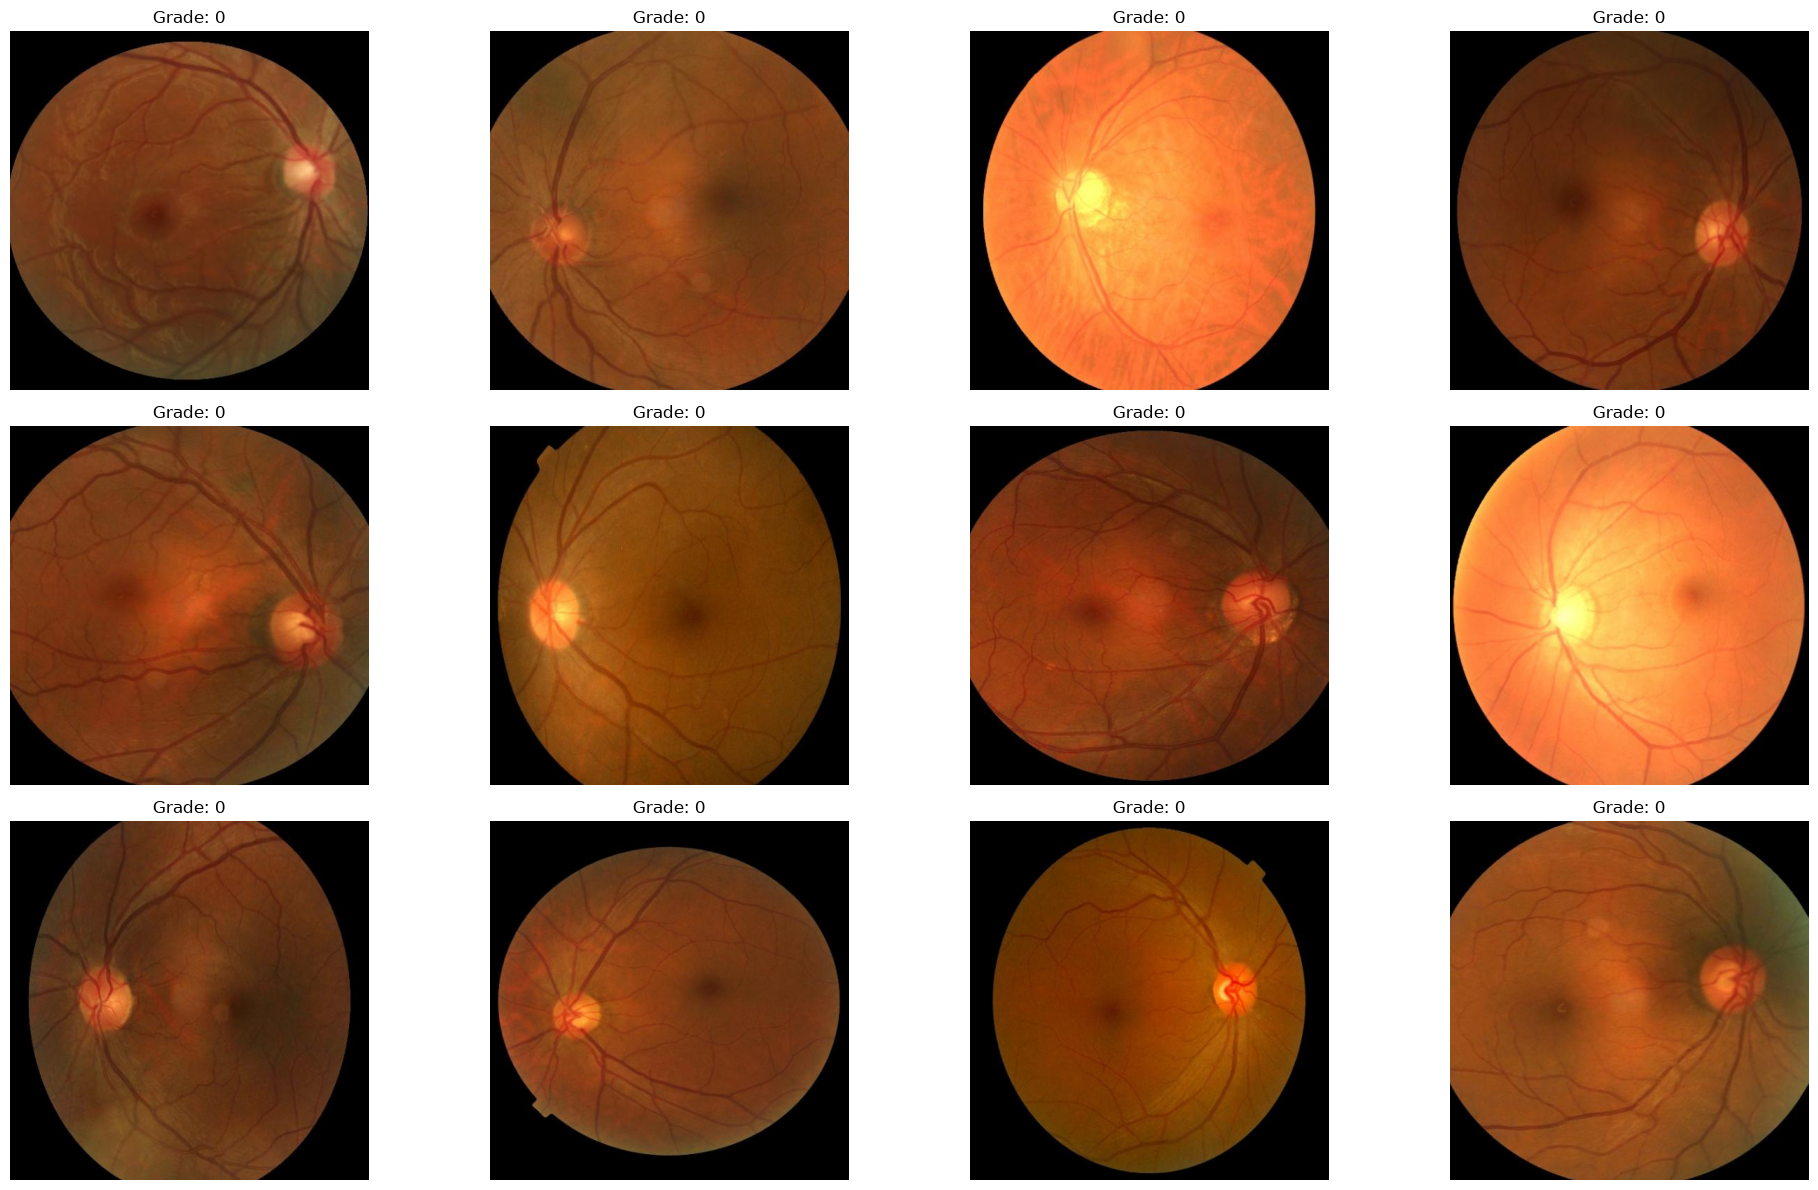

In [20]:
# Cell 3: Display sample augmented retinal images

def display_samples(df, columns=4, rows=3):
    fig = plt.figure(figsize=(5 * columns, 4 * rows))

    number_of_images = min(columns * rows, len(df))

    for i in range(number_of_images):
        image_path = str(df.iloc[i]["id_code"])
        image_id = df.iloc[i]["diagnosis"]

        img_path = os.path.join(
            output_dir, "aug_images", image_path
        )

        img = cv2.imread(img_path)

        if img is None:
            print(f"Could not load image: {img_path}")
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        fig.add_subplot(rows, columns, i + 1)
        plt.title(f"Grade: {image_id}")
        plt.imshow(img)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


display_samples(train_df)

In [21]:
# Preprocess the same augmented image set used by the Kaggle notebook

def get_pad_width(im, new_shape, is_rgb=True):
    pad_diff = new_shape - im.shape[0], new_shape - im.shape[1]

    t, b = math.floor(pad_diff[0] / 2), math.ceil(pad_diff[0] / 2)
    l, r = math.floor(pad_diff[1] / 2), math.ceil(pad_diff[1] / 2)

    if is_rgb:
        pad_width = ((t, b), (l, r), (0, 0))
    else:
        pad_width = ((t, b), (l, r))

    return pad_width


def preprocess_image(image_path, desired_size=224):
    with Image.open(image_path) as im:
        im = im.convert("RGB")
        im = im.resize(
            (desired_size, desired_size),
            resample=Image.Resampling.LANCZOS
        )
        return np.asarray(im, dtype=np.uint8)


augmented_df = train_df.reset_index(drop=True)
image_dir = os.path.join(output_dir, "aug_images")

N = len(augmented_df)

x_train = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(augmented_df["id_code"])):
    image_path = os.path.join(image_dir, str(image_id))

    x_train[i] = preprocess_image(image_path)


# One-hot encode grades 0, 1, 2, 3, 4
y_train = pd.get_dummies(
    augmented_df["diagnosis"]
).reindex(
    columns=[0, 1, 2, 3, 4],
    fill_value=0
).values.astype(np.uint8)


# Convert labels to cumulative multilabel format
y_train_multi = np.empty(y_train.shape, dtype=np.uint8)

y_train_multi[:, 4] = y_train[:, 4]

for i in range(3, -1, -1):
    y_train_multi[:, i] = np.logical_or(
        y_train[:, i],
        y_train_multi[:, i + 1]
    )


# Display results
grade_labels = augmented_df["diagnosis"].to_numpy(dtype=np.int64)

print("Kaggle augmented image array shape:", x_train.shape)
print("One-hot label shape:", y_train.shape)
print("Multilabel shape:", y_train_multi.shape)

print("Original y_train counts:", y_train.sum(axis=0))
print("Multilabel counts:", y_train_multi.sum(axis=0))

100%|██████████| 6594/6594 [02:41<00:00, 40.80it/s]

Kaggle augmented image array shape: (6594, 224, 224, 3)
One-hot label shape: (6594, 5)
Multilabel shape: (6594, 5)
Original y_train counts: [1308 1318 1329 1321 1318]
Multilabel counts: [6594 5286 3968 2639 1318]


In [22]:
# Match the Kaggle DenseNet121 model and training metric

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    BatchNormalization,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)

for layer in base_model.layers[:100]:
    layer.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(5, activation="sigmoid"),
])

# Keras accuracy here is per cumulative label bit; final accuracy is exact grade.
model.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,302,213 (27.86 MB)

 Trainable params: 6,413,381 (24.47 MB)

 Non-trainable params: 888,832 (3.39 MB)

In [23]:
# Reproduce the Kaggle image-level split for score comparison.
# Augmented siblings can cross splits, so this is not a leakage-free test.

from sklearn.model_selection import train_test_split

x_train_full, x_test, y_train_full, y_test = train_test_split(
    x_train,
    y_train_multi,
    test_size=0.2,
    random_state=2019,
)

x_train_partial, x_val, y_train_partial, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.1,
    random_state=2019,
)

print("Training images:", x_train_partial.shape)
print("Validation images:", x_val.shape)
print("Kaggle-protocol test images:", x_test.shape)

Training images: (4747, 224, 224, 3)
Validation images: (528, 224, 224, 3)
Kaggle-protocol test images: (1319, 224, 224, 3)


In [24]:
# Create the Kaggle-style online augmentation generator

from tensorflow.keras.preprocessing.image import ImageDataGenerator

BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    zoom_range=0.15,
    fill_mode="constant",
    cval=0.0,
    horizontal_flip=True,
    vertical_flip=True,
)

data_generator = train_datagen.flow(
    x_train_partial,
    y_train_partial,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=2019,
)

print("Training data generator created with Kaggle augmentation settings.")
print("Batch size:", BATCH_SIZE)
print("Training samples:", len(x_train_partial))

Training data generator created with Kaggle augmentation settings.
Batch size: 32
Training samples: 4747


In [25]:
image_dir = os.path.join(output_dir, "aug_images")

In [26]:
# Compute validation kappa and save the best model

class Metrics(Callback):
    def __init__(self, x_val, y_val, checkpoint_path):
        super().__init__()
        self.x_val = x_val
        self.y_val = y_val
        self.checkpoint_path = checkpoint_path
        self.best_kappa = 0

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0,
        )
        y_val_pred = (probabilities > 0.5).astype(np.int32).sum(axis=1) - 1
        y_val_true = self.y_val.sum(axis=1) - 1
        score = cohen_kappa_score(
            y_val_true,
            y_val_pred,
            weights="quadratic",
        )

        if logs is not None:
            logs["val_kappa"] = score

        if score > self.best_kappa:
            self.best_kappa = score
            self.model.save(self.checkpoint_path)
            print(
                f" - val_kappa: {score:.4f} "
                f"(best model saved to {self.checkpoint_path})"
            )
        else:
            print(f" - val_kappa: {score:.4f}")


best_model_path = os.path.join(PROJECT_DIR, "retfound_model.keras")
kappa_metrics = Metrics(x_val, y_val, best_model_path)

Epoch 1/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.2895 - loss: 0.6658 - val_kappa: 0.5770 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 1345s 9s/step - accuracy: 0.2895 - loss: 0.6658 - val_accuracy: 0.5985 - val_loss: 0.6804 - val_kappa: 0.5770
Epoch 2/15
  1/148 ━━━━━━━━━━━━━━━━━━━━ 22:50 9s/step - accuracy: 0.2812 - loss: 0.4931

d:\project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


 - val_kappa: 0.5529
148/148 ━━━━━━━━━━━━━━━━━━━━ 88s 533ms/step - accuracy: 0.2812 - loss: 0.4931 - val_accuracy: 0.6042 - val_loss: 0.6971 - val_kappa: 0.5529
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.3510 - loss: 0.4170 - val_kappa: 0.7676 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 1401s 9s/step - accuracy: 0.3510 - loss: 0.4170 - val_accuracy: 0.4830 - val_loss: 0.3845 - val_kappa: 0.7676
Epoch 4/15
  1/148 ━━━━━━━━━━━━━━━━━━━━ 24:18 10s/step - accuracy: 0.3750 - loss: 0.4864

d:\project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


 - val_kappa: 0.7722 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 88s 532ms/step - accuracy: 0.3750 - loss: 0.4864 - val_accuracy: 0.4545 - val_loss: 0.3720 - val_kappa: 0.7722
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.4002 - loss: 0.3175 - val_kappa: 0.7736 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 1389s 9s/step - accuracy: 0.4002 - loss: 0.3175 - val_accuracy: 0.5019 - val_loss: 0.2846 - val_kappa: 0.7736
Epoch 6/15
  1/148 ━━━━━━━━━━━━━━━━━━━━ 19:47 8s/step - accuracy: 0.4062 - loss: 0.2347

...

 - val_kappa: 0.9241 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 86s 529ms/step - accuracy: 0.5312 - loss: 0.1560 - val_accuracy: 0.4375 - val_loss: 0.1459 - val_kappa: 0.9241
Epoch 11/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.4568 - loss: 0.1546 - val_kappa: 0.9187
148/148 ━━━━━━━━━━━━━━━━━━━━ 1341s 9s/step - accuracy: 0.4568 - loss: 0.1546 - val_accuracy: 0.3920 - val_loss: 0.1295 - val_kappa: 0.9187
Epoch 12/15
  1/148 ━━━━━━━━━━━━━━━━━━━━ 20:17 8s/step - accuracy: 0.4062 - loss: 0.1415

d:\project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


 - val_kappa: 0.9002
148/148 ━━━━━━━━━━━━━━━━━━━━ 85s 525ms/step - accuracy: 0.4062 - loss: 0.1415 - val_accuracy: 0.3428 - val_loss: 0.1450 - val_kappa: 0.9002
Epoch 13/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.4611 - loss: 0.1251 - val_kappa: 0.9468 (best model saved to d:\project\retfound_model.keras)
148/148 ━━━━━━━━━━━━━━━━━━━━ 1284s 9s/step - accuracy: 0.4611 - loss: 0.1251 - val_accuracy: 0.3864 - val_loss: 0.1015 - val_kappa: 0.9468
Epoch 14/15
  1/148 ━━━━━━━━━━━━━━━━━━━━ 21:25 9s/step - accuracy: 0.3438 - loss: 0.1226

d:\project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


 - val_kappa: 0.9456
148/148 ━━━━━━━━━━━━━━━━━━━━ 86s 527ms/step - accuracy: 0.3438 - loss: 0.1226 - val_accuracy: 0.3939 - val_loss: 0.1006 - val_kappa: 0.9456
Epoch 15/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.4590 - loss: 0.0998 - val_kappa: 0.9019
148/148 ━━━━━━━━━━━━━━━━━━━━ 1406s 10s/step - accuracy: 0.4590 - loss: 0.0998 - val_accuracy: 0.2784 - val_loss: 0.1223 - val_kappa: 0.9019
Kaggle-protocol test grade accuracy: 0.8574677786201668
Kaggle-protocol test grade accuracy (%): 85.75
Kaggle-protocol test quadratic kappa: 0.9456943070603807


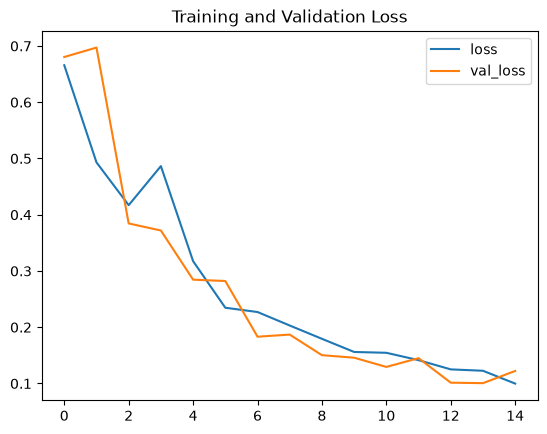

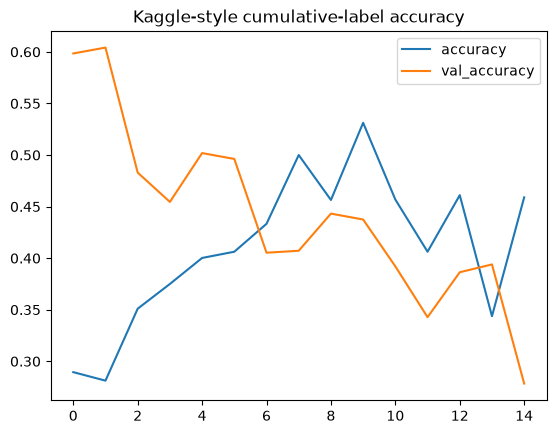

In [27]:
# Train and evaluate using the Kaggle model recipe

history = model.fit(
    data_generator,
    steps_per_epoch=len(x_train_partial) // BATCH_SIZE,
    epochs=15,
    validation_data=(x_val, y_val),
    callbacks=[kappa_metrics],
)

best_model = tf.keras.models.load_model(best_model_path)

# Report exact-grade accuracy and quadratic kappa, as in the Kaggle evaluation.
y_pred_probabilities = best_model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = (y_pred_probabilities > 0.5).astype(np.int32).sum(axis=1) - 1
y_true = y_test.sum(axis=1) - 1

accuracy = accuracy_score(y_true, y_pred)
test_kappa = cohen_kappa_score(y_true, y_pred, weights="quadratic")
print("Kaggle-protocol test grade accuracy:", accuracy)
print("Kaggle-protocol test grade accuracy (%):", round(accuracy * 100, 2))
print("Kaggle-protocol test quadratic kappa:", test_kappa)

with open(os.path.join(PROJECT_DIR, "retfound_history.json"), "w") as history_file:
    json.dump(history.history, history_file)

history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot(title="Training and Validation Loss")
plt.show()
history_df[["accuracy", "val_accuracy"]].plot(
    title="Kaggle-style cumulative-label accuracy"
)
plt.show()

Confusion matrix:
[[217  33   0   0   0]
 [ 14 240  17   3   0]
 [  0  26 210  22   6]
 [  1   4  19 233  13]
 [  0   3   6  21 231]]


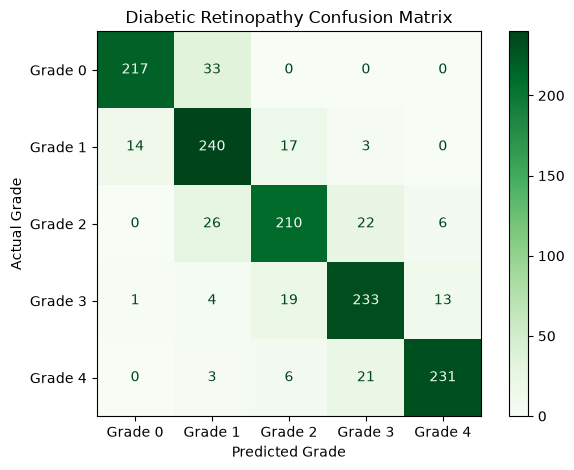

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

print("Confusion matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]
)

disp.plot(cmap=plt.cm.Greens, values_format="d")
plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("Diabetic Retinopathy Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred)
print("\nAccuracy:", accuracy)
print("Accuracy (%):", round(accuracy * 100, 2))


Accuracy: 0.8574677786201668
Accuracy (%): 85.75


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
micro_precision = precision_score(y_true, y_pred, average="micro", zero_division=0)
weighted_precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)

print("Macro Precision:", macro_precision)
print("Micro Precision:", micro_precision)
print("Weighted Precision:", weighted_precision)

macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
micro_recall = recall_score(y_true, y_pred, average="micro", zero_division=0)
weighted_recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)

print("Macro Recall:", macro_recall)
print("Micro Recall:", micro_recall)
print("Weighted Recall:", weighted_recall)

macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
micro_f1 = f1_score(y_true, y_pred, average="micro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)
print("Weighted F1:", weighted_f1)

Macro Precision: 0.862423466887682
Micro Precision: 0.8574677786201668
Weighted Precision: 0.8607930543203999
Macro Recall: 0.8574774776882
Micro Recall: 0.8574677786201668
Weighted Recall: 0.8574677786201668
Macro F1: 0.8589760502425949
Micro F1: 0.8574677786201668
Weighted F1: 0.8581493606279759


## Archived Kaggle-only alternative (not part of the local pipeline)

This archived original uses `/kaggle/...` paths and the removed `fit_generator` API. Its model recipe is now adapted for the local TensorFlow 2/Keras pipeline in the executable cells above; the original source is preserved here for reference.

```python
# Complete RetFound-style implementation for TensorFlow 1.x
import json
import math
import os
import cv2
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from keras import layers
from keras.models import Sequential
from keras.optimizers import Adam
from keras.callbacks import Callback, ModelCheckpoint
from keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from keras.applications import DenseNet121

# Set random seeds for reproducibility
np.random.seed(2019)
tf.set_random_seed(2019)

# ====================== DATA PREPARATION ======================
# Create directories
os.makedirs('/kaggle/working/ddr-equal/train_images', exist_ok=True)

# Load dataset
file_path = '/kaggle/input/ddrdataset/DR_grading.csv'
data = pd.read_csv(file_path)

# Prepare image dictionary
image_dict = {}
LABEL_SIZE = 236

for i in data.index:
    image_dict[data['id_code'][i]] = data['diagnosis'][i]

# Balance classes
count = [0, 0, 0, 0, 0]
rows = []

for i in data.index:
    source_file_path = f'/kaggle/input/ddrdataset/DR_grading/DR_grading/' + data['id_code'][i]
    destination_file_path = '/kaggle/working/ddr-equal/train_images/'
    
    if count[data['diagnosis'][i]] < LABEL_SIZE and os.path.exists(source_file_path):
        rows.append([data['id_code'][i], data['diagnosis'][i]])
        shutil.copy(source_file_path, destination_file_path)
        count[data['diagnosis'][i]] += 1

# Save balanced dataset
columns = ['id_code', 'diagnosis']
df = pd.DataFrame(rows, columns=columns)
df.to_csv('/kaggle/working/ddr-equal/train.csv', index=False)

# Data augmentation
datagen = ImageDataGenerator(
    zoom_range=0.15,
    fill_mode='constant',
    cval=0.,
    horizontal_flip=True,
    vertical_flip=True,
)

os.makedirs('/kaggle/working/ddr-equal/aug_images', exist_ok=True)

for j in range(df.shape[0]):
    id_code = df['id_code'][j]
    diagnosis = str(df['diagnosis'][j])
    img = load_img(f'/kaggle/working/ddr-equal/train_images/{id_code}') 
    x = img_to_array(img)
    x = x.reshape((1,) + x.shape)
    
    i = 0
    for batch in datagen.flow(x, batch_size=1, save_to_dir='/kaggle/working/ddr-equal/aug_images', 
                            save_prefix=diagnosis + '_', save_format='jpg'):
        i += 1
        if i > 5:  # Generate 6 augmented versions
            break

# Create augmented dataset CSV
augmented_rows = []
aug_dir = '/kaggle/working/ddr-equal/aug_images'

for augmented_img_name in os.listdir(aug_dir):
    augmented_rows.append([augmented_img_name, int(augmented_img_name[0])])

df_augmented = pd.DataFrame(augmented_rows, columns=columns)
df_augmented.to_csv('/kaggle/working/ddr-equal/aug.csv', index=False)

# Load augmented dataset
train_df = pd.read_csv('/kaggle/working/ddr-equal/aug.csv')
print(f"Augmented dataset shape: {train_df.shape}")

# ====================== DATA PREPROCESSING ======================
def preprocess_image(image_path, desired_size=224):
    im = Image.open(image_path)
    im = im.resize((desired_size, desired_size), resample=Image.LANCZOS)
    return im

# Prepare training data
N = train_df.shape[0]
x_train = np.empty((N, 224, 224, 3), dtype=np.uint8)

for i, image_id in enumerate(tqdm(train_df['id_code'])):
    x_train[i, :, :, :] = preprocess_image(
        f'/kaggle/working/ddr-equal/aug_images/{image_id}'
    )

y_train = pd.get_dummies(train_df['diagnosis']).values

# Convert to multilabel format
y_train_multi = np.empty(y_train.shape, dtype=y_train.dtype)
y_train_multi[:, 4] = y_train[:, 4]

for i in range(3, -1, -1):
    y_train_multi[:, i] = np.logical_or(y_train[:, i], y_train_multi[:, i+1])

print("Original y_train:", y_train.sum(axis=0))
print("Multilabel version:", y_train_multi.sum(axis=0))

# Train/val/test split
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x_train, y_train_multi, 
    test_size=0.2,
    random_state=2019
)

x_train_partial, x_val, y_train_partial, y_val = train_test_split(
    x_train_full, y_train_full, 
    test_size=0.1, 
    random_state=2019
)

# ====================== MODEL DEFINITION ======================
BATCH_SIZE = 32

def create_datagen():
    return ImageDataGenerator(
        zoom_range=0.15,
        fill_mode='constant',
        cval=0.,
        horizontal_flip=True,
        vertical_flip=True,
    )

data_generator = create_datagen().flow(x_train_partial, y_train_partial, batch_size=BATCH_SIZE, seed=2019)

class RetinaMetrics(Callback):
    def on_train_begin(self, logs={}):
        self.val_kappas = []
        self.best_kappa = 0

    def on_epoch_end(self, epoch, logs={}):
        X_val, y_val = self.validation_data[:2]
        y_val = y_val.sum(axis=1) - 1
        
        y_pred = self.model.predict(X_val, verbose=0) > 0.5
        y_pred = y_pred.astype(int).sum(axis=1) - 1

        _val_kappa = cohen_kappa_score(
            y_val,
            y_pred, 
            weights='quadratic'
        )
        
        self.val_kappas.append(_val_kappa)
        print(f"val_kappa: {_val_kappa:.4f}")
        
        if _val_kappa > self.best_kappa:
            print(f"Validation Kappa improved from {self.best_kappa:.4f} to {_val_kappa:.4f}. Saving model.")
            self.best_kappa = _val_kappa
            self.model.save('retfound_model.h5')

        return

def build_retfound_model(input_shape=(224, 224, 3), num_classes=5):
    # Base model (using DenseNet121 which is available in TF 1.x)
    base_model = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=input_shape
    )
    
    # Freeze initial layers
    for layer in base_model.layers[:100]:
        layer.trainable = False
    
    # Custom head for diabetic retinopathy grading
    model = Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='sigmoid')
    ])
    
    # Optimizer
    optimizer = Adam(lr=3e-4)
    
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model

model = build_retfound_model()
model.summary()

# ====================== TRAINING ======================
retina_metrics = RetinaMetrics()

history = model.fit_generator(
    data_generator,
    steps_per_epoch=x_train_partial.shape[0] // BATCH_SIZE,
    epochs=15,
    validation_data=(x_val, y_val),
    callbacks=[retina_metrics],
    verbose=1
)

# ====================== EVALUATION ======================
# Load best model
best_model = tf.keras.models.load_model('retfound_model.h5')

# Predict on test set
y_pred = best_model.predict(x_test) > 0.5
y_pred = y_pred.astype(int).sum(axis=1) - 1
y_true = y_test.sum(axis=1) - 1

# Metrics
print("\nFinal Evaluation on Test Set:")
print("="*50)
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Quadratic Kappa: {cohen_kappa_score(y_true, y_pred, weights='quadratic'):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_true, y_pred, average='weighted'):.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, cmap='Blues')

ax.set_xlabel('Predicted labels', fontsize=12)
ax.set_ylabel('True labels', fontsize=12)
ax.set_title('Confusion Matrix', fontsize=14)
ax.figure.colorbar(im, ax=ax)

plt.show()

# Save training history
with open('retfound_history.json', 'w') as f:
    json.dump(history.history, f)

# Plot training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['acc'], label='Train Accuracy')
plt.plot(history.history['val_acc'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()
```
